# Luthera Wanderers

The escaped asteroids have been identified in escaped asteroids h5 file.

Now I need to read the relevant pval_?????.h5 log and track where the asteroid wandered.


In [1]:
import datetime as datetime
from pathlib import Path
import pandas as pd
import numpy as np
import h5py as h5

import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm

xlabel_time = 'Years after start of simulation [$10^9 ~ yr$]'

# boundary values
# semi major axis a
a_min = 1.8
a_max = 3.95
# eccentricity e
e_min = 0.0
e_max = 0.34
# inclination i (radians)
i_min = 0.0
i_max = 0.55

# indices in the particles array
SMA = 6
ECC = 7
INC = 8


In [2]:
# Read the escaped asteroids file
project_dir = Path('../../asteroid_data/mc_pm6_3/')

ea_file = pd.HDFStore(project_dir / 'escaped_asteroids.h5')

ea_mmc3 = ea_file.get('escaped_asteroids')
ea_metadata = ea_file.get_storer('escaped_asteroids').attrs.metadata

ea_file.close()

## Calculate the proportions of asteroids occupying various orbits at the end of the simulation


In [48]:
plot_dir = project_dir / 'plots'
# Calculate the proportions of asteroids
integration_time = ea_metadata['integration_time']
simulated = ea_metadata['simulated']
escaped = ea_metadata['escaped']
inner_solar = ea_metadata['inner_solar']
outer_solar = ea_metadata['outer_solar']
avg_walltime = ea_metadata['avg_walltime']

inners = ea_sma[(ea_sma.min_val<a_min) & (ea_sma.max_val<=a_max)]
inner_solar = len(inners)
outers = ea_sma[(ea_sma.min_val>=a_min) & (ea_sma.max_val > a_max)]
outer_solar = len(outers)

solar_i = len(ea_sma[(ea_sma.min_val==0.0) & (ea_sma.max_val<=a_max)])
solar_ii = len(ea_sma[(ea_sma.min_val==0.0) & (ea_sma.max_val>a_max)])
only_inner = len(ea_sma[(ea_sma.min_val>0.0) & (ea_sma.min_val<a_min) & (ea_sma.max_val<=a_max)])
only_outer = len(ea_sma[(ea_sma.min_val>a_min) & (ea_sma.max_val>=a_max)])
both = ea_sma[(ea_sma.min_val<a_min) & (ea_sma.min_val!=0.0) & (ea_sma.max_val>a_max)]
combined = len(both)

ea_leftovers=ea_sma.index.difference(ea_sma[(ea_sma.min_val<a_min) & (ea_sma.max_val>a_max)].index.union(inners.index.union(outers.index))) 

print(f'All ea_sma {len(ea_sma)}, Inners {inner_solar}, Outers {outer_solar}, Both {combined}, ^in&out {len(ea_leftovers)}')
print(f'Unaccounted {len(ea_sma) - inner_solar - outer_solar - combined}')

print(f'{simulated} test particles simulated for {integration_time:2.1e} years')
print(f'{len(ea_sma)} ({len(ea_sma)/simulated:.1%}) particles crossed the family boundaries of {a_min} and {a_max} AU')


All ea_sma 16768, Inners 9018, Outers 3865, Both 190, ^in&out 0
Unaccounted 3695
57135 test particles simulated for 3.0e+09 years
16768 (29.3%) particles crossed the family boundaries of 1.8 and 3.95 AU


[9018, 190, 3865] 13073


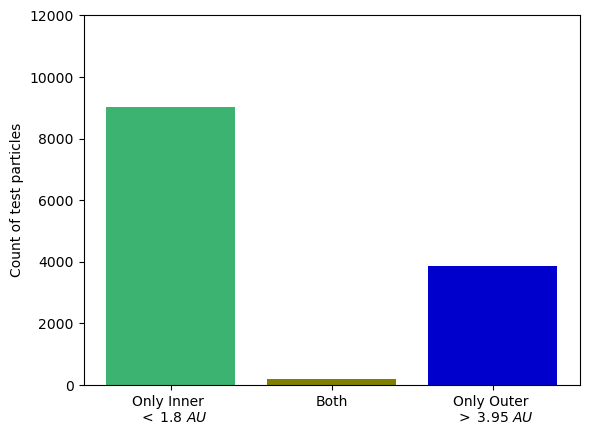

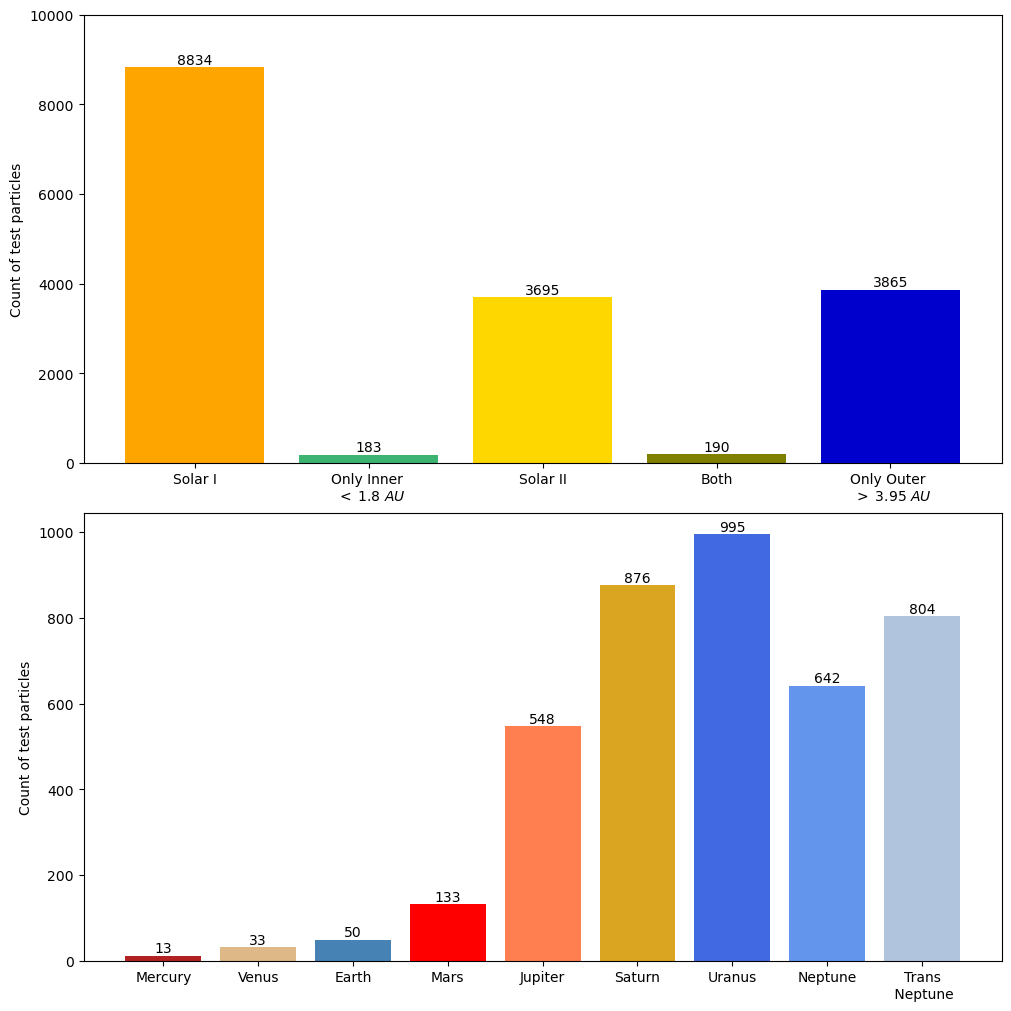

In [47]:
categories = [f'Only Inner \n $<~{1.8} ~AU$', 'Both', f'Only Outer \n $>~{3.95} ~AU$']
counts = [inner_solar, combined, outer_solar]
print(counts, sum(counts))

bar_colors = ['mediumseagreen', 'olive', 'mediumblue' ]
plt.bar(categories, counts, color=bar_colors)
plt.ylim(0,12000)
plt.ylabel('Count of test particles')
plt.savefig(plot_dir / "wanderers_io_count.png", dpi=300)
plt.show()


fig = plt.figure(figsize=(10, 10), layout="constrained")
spec = fig.add_gridspec(ncols=1, nrows=2)
ax1 = fig.add_subplot(spec[0, 0])

categories = ['Solar I', f'Only Inner \n $<~{1.8} ~AU$', 'Solar II', 'Both', f'Only Outer \n $>~{3.95} ~AU$']
counts = [solar_i, only_inner, solar_ii, combined, only_outer]
bar_colors = ['orange', 'mediumseagreen', 'gold', 'olive', 'mediumblue']
ax1.set_ylim(0,10000)
bars = ax1.bar(categories, counts, color=bar_colors)
ax1.bar_label(bars)
ax1.set_ylabel('Count of test particles')

planets = ['Mercury', 'Venus', 'Earth', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune']
sma_au = [0.3871, 0.7233, 1, 1.5273, 5.2028, 9.5388, 19.1914, 30.0611]
plan_colors = ['firebrick', 'burlywood', 'steelblue', 'red', 'coral', 'goldenrod', 'royalblue', 'cornflowerblue', 'lightsteelblue']

crossing_count = []
for index, plan in enumerate(planets):
    if index == 0:
        crossing_count.append(len(ea_sma[ (ea_sma.min_val>0.0) & (ea_sma.min_val<sma_au[index])]))
    elif index <= 3:
        crossing_count.append(len(ea_sma[(ea_sma.min_val>sma_au[index-1]) & (ea_sma.min_val<sma_au[index])]))
    else:
        crossing_count.append(len(ea_sma[(ea_sma.min_val>a_min) & (ea_sma.max_val>sma_au[index-1]) & (ea_sma.max_val<sma_au[index])]))
        
planets.append('Trans\n Neptune')
crossing_count.append(len(ea_mmc3[(ea_mmc3.parameter==6) & (ea_mmc3.min_val>a_min) & (ea_mmc3.max_val>sma_au[-1])]))

ax2 = fig.add_subplot(spec[1, 0])
ax2.set_ylabel('Count of test particles')
bars = ax2.bar(planets, crossing_count, color=plan_colors)
ax2.bar_label(bars)

plt.savefig(plot_dir / "iob_planet_crossings.png", dpi=300)
plt.show()


In [12]:
ea_mmc3[(ea_mmc3.parameter==6)].describe()

,particle_number,parameter,parameter_value,integration_year,min_val,max_val
count,16768.000000,16768.0,16768.000000,1.676800e+04,16768.000000,16768.000000
mean,9.397960,6.0,4.743780,6.018328e+09,0.651010,10.453547
std,0.775182,0.0,7.788436,5.685118e+09,1.685555,12.937287
min,8.000000,6.0,-2.071092,1.000000e+04,-153.251723,1.842628
25%,9.000000,6.0,0.000000,9.391245e+08,0.000000,2.789724
50%,10.000000,6.0,0.000000,3.993053e+09,0.000000,3.312487
75%,10.000000,6.0,6.661930,1.032964e+10,0.701790,12.731277
max,10.000000,6.0,98.535587,1.884954e+10,3.902529,98.535587


In [13]:
ea_grouped1 = ea_mmc3[ea_mmc3.parameter==6][['ast_name','vectors']].groupby('ast_name').size()

asteroid_track_names = ea_grouped1[ea_grouped1 > (65*0.75)].index

In [14]:
len(asteroid_track_names)

138

In [13]:
escaped_ast_sim = ea_mmc3[ea_mmc3.ast_name.isin(asteroid_track_names)][['ast_name','sim_no','particle_number']]
escaped_ast_sim = escaped_ast_sim.drop_duplicates()

In [14]:
escaped_ast_sim

,ast_name,sim_no,particle_number
2,2002 FL44,00148,10
7,2002 FL44,00174,10
12,2002 FL44,00191,10
18,2002 FL44,00167,10
25,2002 PX190,00389,10
...,...,...,...
36075,2009 SN2,10945,10
36078,2015 PC254,10935,9
36079,2009 SN2,10935,10
36081,2015 PC254,10947,9


1999 RG252


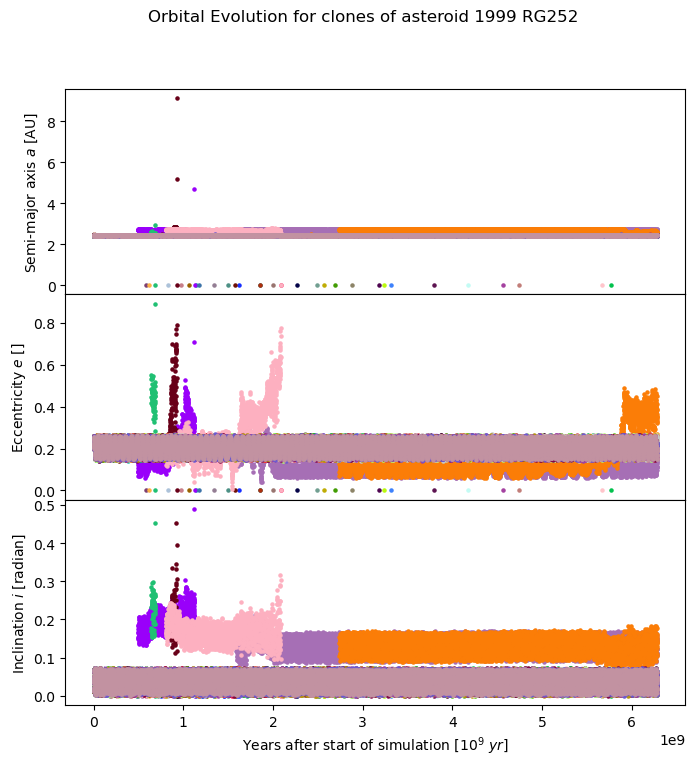

In [15]:
results_dir = project_dir / 'fawkes_pvals'

for ast_name in asteroid_track_names:
    ast_array = escaped_ast_sim.loc[escaped_ast_sim.ast_name==ast_name].values
    print(ast_name)
    int_values = None
    plot_vals = np.zeros([10000,len(ast_array), 11])
    xkcd_colors = list(mpl.colors.XKCD_COLORS.keys())
    
    # plt.style.use('fivethirtyeight')
    fig = plt.figure(figsize=(8, 8))
    fig.suptitle(f'Orbital Evolution for clones of asteroid {ast_name} ')
    gs = fig.add_gridspec(3, hspace=0)
    (ax1, ax2, ax3) = gs.subplots(sharex=True)

    for p_no, (_, sim_file, particle_no) in enumerate(ast_array):
        with h5.File(results_dir / f"pvals_{sim_file:05}.h5", 'r') as sim_log:
            # Unpack the H5
            # Store the first array of time steps (they're duplicated across H5's)
            if int_values is None:
                int_values = sim_log['integration_time_values'][()]
            #Copy the values for the particle
            part_values = sim_log['particle_values'][()]
            sma_0 = np.where(part_values[:, particle_no - 8, SMA] == 0.0)[0]
            if len(sma_0) > 0:
                graph_end = sma_0[0] + 1
            else:
                graph_end = len(part_values)
            color = xkcd_colors[p_no*13]
            ax1.scatter(int_values[:graph_end], part_values[:graph_end, particle_no - 8, SMA], s=5, marker='o', c=color)
            ax2.scatter(int_values[:graph_end], part_values[:graph_end, particle_no - 8, ECC], s=5, marker='o', c=color)
            ax3.scatter(int_values[:graph_end], part_values[:graph_end,  particle_no - 8, INC], s=5, marker='o', c=color)

    plt.xlabel(xlabel_time)
    ax1.set_ylabel("Semi-major axis $a$ [AU]")
    ax1.label_outer()
    ax2.set_ylabel("Eccentricity $e$ []")
    ax2.label_outer()
    ax3.set_ylabel("Inclination $i$ [radian]")
    plt.savefig(plot_dir / f"orb_evol_{ast_name.replace(' ','_')}.png", dpi=300)
    plt.show()
    break
    


In [44]:

test_log = h5.File(results_dir / "pvals_00148.h5", 'r')

int_values = test_log['integration_time_values'][()]
int_values = int_values/(2*np.pi)

part_values = test_log['particle_values'][()]
sim_energy_values = test_log['sim_energy_values'][()]

print(int_values.shape, part_values.shape, sim_energy_values.shape)
    
print(np.mean(sim_energy_values))
test_log.close()

(10000,) (10000, 3, 11) (10000,)
-0.00010885564500305634
